✓ Found 1 PDF files in ..\data\lectures\DL

EXTRACTING TEXT FROM DL PAPERS

Found 1 PDF files

Processing: Deep Learning - Lecturs All in One.pdf


Cannot set gray non-stroke color because /'P7' is an invalid float value
Cannot set gray non-stroke color because /'P15' is an invalid float value
Cannot set gray non-stroke color because /'P43' is an invalid float value
Cannot set gray non-stroke color because /'P51' is an invalid float value
Cannot set gray non-stroke color because /'P68' is an invalid float value
Cannot set gray non-stroke color because /'P76' is an invalid float value
Cannot set gray non-stroke color because /'P94' is an invalid float value
Cannot set gray non-stroke color because /'P102' is an invalid float value
Cannot set gray non-stroke color because /'P120' is an invalid float value
Cannot set gray non-stroke color because /'P128' is an invalid float value
Cannot set gray non-stroke color because /'P155' is an invalid float value
Cannot set gray non-stroke color because /'P163' is an invalid float value
Cannot set gray non-stroke color because /'P184' is an invalid float value
Cannot set gray non-stroke color 

  ✓ Extracted 434 pages

Total pages extracted: 434

✓ Text extraction complete! Saved to ..\data\extracted_text_dl.json

First page preview:
------------------------------------------------------------
Guru sitha noridawa
Welawa nowaradawa
Bathi pem upadawa
Akuru uganiw kumaru sodawa
------------------------------------------------------------
CONTENT ANALYSIS - DL PAPERS

Total pages: 434
Total characters: 111,169
Total words: 17,538
Unique words: 3,666
Average words per page: 40

TOP 20 MOST COMMON WORDS
learning             :   249
deep                 :   154
se4050               :   121
introduction         :   103
dharshana            :    94
kasthurirathna       :    94
neural               :    91


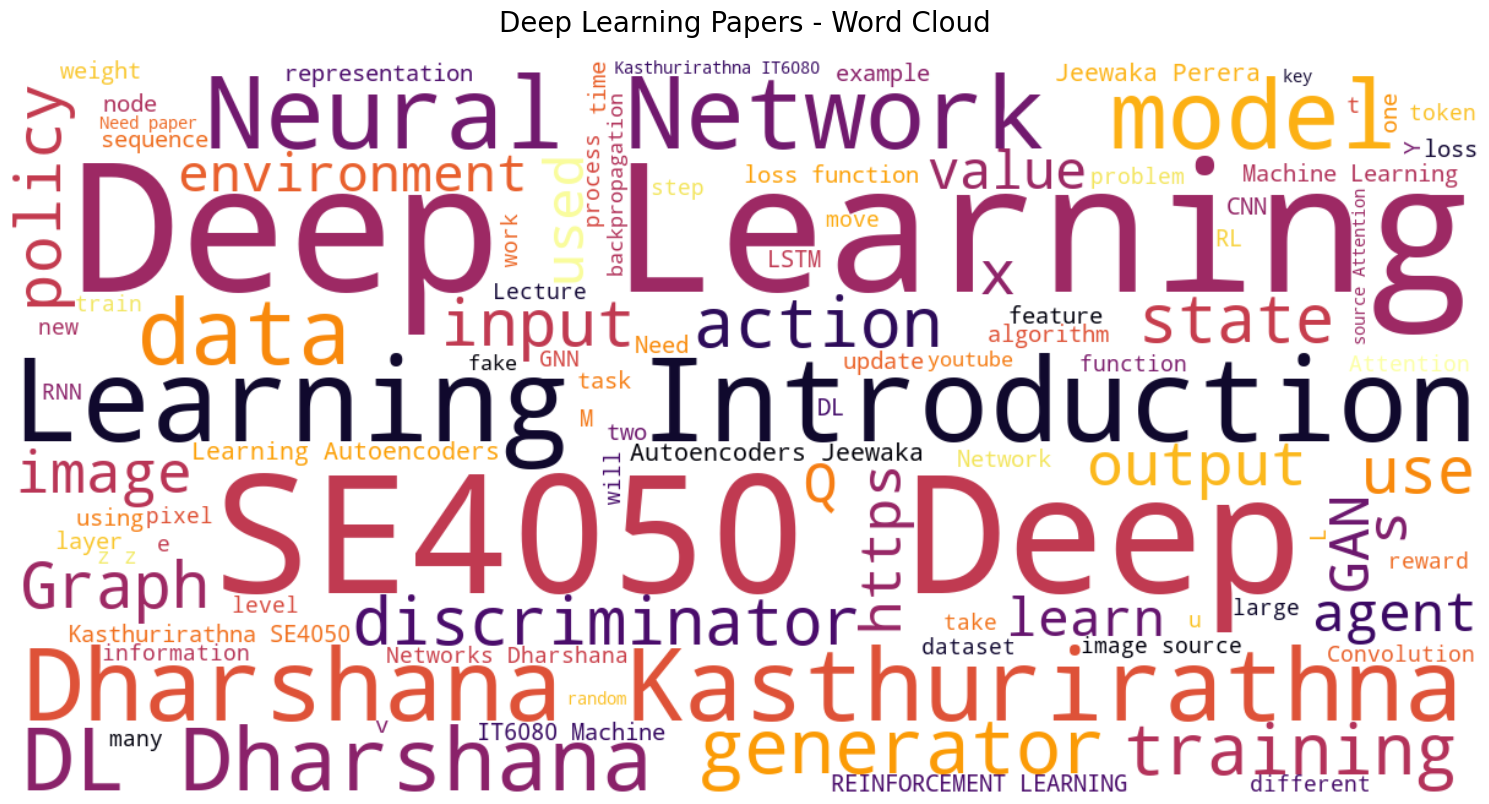


✓ Analysis complete! Word cloud saved to ../outputs/wordcloud_dl.png
PREPARING TRAINING DATA

✓ Created 153 text chunks
✓ Average chunk size: 771 characters

Sample chunk:
------------------------------------------------------------
Guru sitha noridawa
Welawa nowaradawa
Bathi pem upadawa
Akuru uganiw kumaru sodawa

SE4050 – Deep Learning
Introduction to SE4050
SE4050 | Deep Learning | Introduction to DL | Dr. Mahima Weerasinghe, MIET

Content
• Meta data about the SE 4050
Introduction to the team
Module description & Blooms tax...
------------------------------------------------------------

✓ Created 153 training examples
✓ Saved to ..\data\training_data_dl.json

Example training data:
{
  "instruction": "Explain deep learning concepts based on academic research.",
  "input": "Deep Learning Research - Section 1",
  "output": "Guru sitha noridawa\nWelawa nowaradawa\nBathi pem upadawa\nAkuru uganiw kumaru sodawa\n\nSE4050 – Deep Learning\nIntroduction to SE4050\nSE4050 | Deep Learning 

C:\Users\Dilun\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MODEL SETUP

Loading model: TinyLlama/TinyLlama-1.1B-Chat-v1.0
Using device: cpu
✓ Model loaded successfully!

MODEL CONFIGURATION
trainable params: 1,126,400 || all params: 1,101,174,784 || trainable%: 0.1023
DATASET PREPARATION

✓ Dataset size: 153 examples

Sample formatted prompt:
------------------------------------------------------------
### Instruction:
Explain deep learning concepts based on academic research.

### Input:
Deep Learning Research - Section 1

### Response:
Guru sitha noridawa
Welawa nowaradawa
Bathi pem upadawa
Akuru uganiw kumaru sodawa

SE4050 – Deep Learning
Introduction to SE4050
SE4050 | Deep Learning | Introdu...
------------------------------------------------------------


Tokenizing dataset: 100%|██████████| 153/153 [00:00<00:00, 710.91 examples/s]



✓ Tokenization complete!
✓ Tokenized dataset size: 153 examples



No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


TRAINING CONFIGURATION

✓ Trainer initialized
✓ Training on 153 examples
✓ Total training steps: 57
STARTING TRAINING


Step,Training Loss
10,2.415200
20,2.265400
30,2.364700
40,2.264200
50,2.177500



TRAINING COMPLETE!

✓ Model saved to ../models/dl_papers_lora_final
MODEL TESTING

Prompt: What is deep learning?
------------------------------------------------------------
Response: Deep Learning:
1. Convolutional Neural Networks (CNN)
2. Recurrent Neural Networks (RNN)
3. Generative Adversarial Networks (GAN)
4. Neural Architecture Search (NAS)

5. Transfer Learning

6. Domain Adaptation

7. Unsupervised Learning

8. Autoencoders

9. Attention Mechanisms

10. Neural Architectu...

Prompt: Explain convolutional neural networks
------------------------------------------------------------
Response: Response:...

Prompt: What are the key challenges in training deep neural networks?
------------------------------------------------------------
Response: Deep learning has been the focus of much research in recent years. However, deep learning is still a relatively new field, and researchers are still struggling with the following challenges:

1. Lack of Standardization: Deep learning is 

In [ ]:
# %% [markdown]
# # Model Training on DL Papers
# Training a language model on Deep Learning papers

# %% [python]
# Install required packages 
# !pip install PyPDF2 pdfplumber langchain sentence-transformers transformers datasets accelerate peft bitsandbytes torch matplotlib wordcloud

import PyPDF2
import pdfplumber
import pandas as pd
from pathlib import Path
import json
import os

# %% [python]
# Option: Load from existing extracted_text_dl.json if available
import json
from pathlib import Path

extracted_file = Path('../data/extracted_text_dl.json')

if extracted_file.exists() and extracted_file.stat().st_size > 100:  # Check if file has content
    print("Loading from existing extracted_text_dl.json...")
    with open(extracted_file, 'r', encoding='utf-8') as f:
        all_extracted_data = json.load(f)
    if all_extracted_data:
        print(f"✓ Loaded {len(all_extracted_data)} pages from existing file")
    else:
        print("⚠ File exists but is empty, will search for PDFs...")
        all_extracted_data = None
else:
    all_extracted_data = None

if not all_extracted_data:
    # Try multiple possible locations for DL papers
    possible_paths = [
        Path("../data/papers/DL"),
        Path("../data/lectures/DL"),
        Path("../data/DL"),
    ]
    
    dl_papers_path = None
    for path in possible_paths:
        if path.exists():
            pdf_files = list(path.glob("*.pdf"))
            if pdf_files:
                dl_papers_path = path
                print(f"✓ Found {len(pdf_files)} PDF files in {path}")
                break
    
    if not dl_papers_path:
        print("\n" + "=" * 60)
        print("ERROR: No DL papers found!")
        print("=" * 60)
        print("\nSearched in:")
        for path in possible_paths:
            print(f"  - {path.absolute()} (exists: {path.exists()})")
        print("\nPlease:")
        print("1. Place PDF files in one of the above locations")
        print("2. Or specify the correct path")
        raise FileNotFoundError("No PDF files found in any expected location")
    
    all_extracted_data = []

    # Extract text from all PDF files
    def extract_text_from_pdf(pdf_path):
        """Extract text from PDF using pdfplumber for better formatting"""
        text_content = []
        
        try:
            with pdfplumber.open(pdf_path) as pdf:
                for i, page in enumerate(pdf.pages):
                    text = page.extract_text()
                    if text:  # Only add non-empty pages
                        text_content.append({
                            'page': i + 1,
                            'content': text,
                            'file': pdf_path.name
                        })
        except Exception as e:
            print(f"Error processing {pdf_path.name}: {e}")
        
        return text_content

    print("\n" + "=" * 60)
    print("EXTRACTING TEXT FROM DL PAPERS")
    print("=" * 60)

    # Get all PDF files
    pdf_files = list(dl_papers_path.glob("*.pdf"))
    print(f"\nFound {len(pdf_files)} PDF files\n")

    # Extract from each PDF
    for pdf_file in pdf_files:
        print(f"Processing: {pdf_file.name}")
        extracted = extract_text_from_pdf(pdf_file)
        all_extracted_data.extend(extracted)
        print(f"  ✓ Extracted {len(extracted)} pages")

    print(f"\n{'='*60}")
    print(f"Total pages extracted: {len(all_extracted_data)}")
    print(f"{'='*60}")

    # Save extracted text
    output_path = Path('../data/extracted_text_dl.json')
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with open(output_path, 'w', encoding='utf-8') as f:
        json.dump(all_extracted_data, f, ensure_ascii=False, indent=2)

    print(f"\n✓ Text extraction complete! Saved to {output_path}")

    # Preview first page
    if all_extracted_data:
        print(f"\nFirst page preview:\n{'-'*60}")
        print(all_extracted_data[0]['content'][:500])
        print(f"{'-'*60}")

# %% [python]
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import re

# Create outputs directory
output_dir = Path('../outputs')
output_dir.mkdir(parents=True, exist_ok=True)

# Check if we have data before proceeding
if not all_extracted_data:
    print("\n" + "=" * 60)
    print("ERROR: No data to analyze!")
    print("=" * 60)
    raise ValueError("No extracted data available. Please check PDF extraction step.")

# Combine all text
full_text = "\n\n".join([page['content'] for page in all_extracted_data])

# Basic statistics
words = full_text.lower().split()
word_freq = Counter(words)

print("=" * 60)
print("CONTENT ANALYSIS - DL PAPERS")
print("=" * 60)
print(f"\nTotal pages: {len(all_extracted_data)}")
print(f"Total characters: {len(full_text):,}")
print(f"Total words: {len(words):,}")
print(f"Unique words: {len(set(words)):,}")
print(f"Average words per page: {len(words) / len(all_extracted_data):.0f}")

# Top 20 most common words
print("\n" + "=" * 60)
print("TOP 20 MOST COMMON WORDS")
print("=" * 60)
for word, freq in word_freq.most_common(20):
    if len(word) > 3:  # Filter short words
        print(f"{word:20s} : {freq:5d}")

# Generate word cloud
wordcloud = WordCloud(width=1200, height=600, background_color='white', 
                      max_words=100, colormap='inferno').generate(full_text)

plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Deep Learning Papers - Word Cloud', fontsize=20, pad=20)
plt.tight_layout()
plt.savefig('../outputs/wordcloud_dl.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Analysis complete! Word cloud saved to ../outputs/wordcloud_dl.png")

# %% [python]
from langchain.text_splitter import RecursiveCharacterTextSplitter

print("=" * 60)
print("PREPARING TRAINING DATA")
print("=" * 60)

# Check if we have data
if not full_text or len(full_text.strip()) == 0:
    raise ValueError("No text content available for training!")

# Split text into chunks for training
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n", ". ", "! ", "? ", " ", ""]
)

chunks = text_splitter.split_text(full_text)

if not chunks:
    raise ValueError("No chunks created from text!")

print(f"\n✓ Created {len(chunks)} text chunks")
print(f"✓ Average chunk size: {sum(len(c) for c in chunks) / len(chunks):.0f} characters")
print(f"\nSample chunk:\n{'-'*60}\n{chunks[0][:300]}...\n{'-'*60}")

# Create training dataset in instruction format
training_data = []

# Create varied instruction templates for better training
instruction_templates = [
    "Explain deep learning concepts based on academic research.",
    "Discuss deep learning architectures and techniques.",
    "Describe key concepts in deep learning and their applications.",
    "Summarize important findings in deep learning research.",
    "Explain neural network fundamentals and advanced topics.",
    "Discuss deep learning optimization and training strategies.",
]

# Create training examples
for i, chunk in enumerate(chunks):
    # Vary instructions to avoid overfitting
    instruction = instruction_templates[i % len(instruction_templates)]
    
    training_data.append({
        "instruction": instruction,
        "input": f"Deep Learning Research - Section {i+1}",
        "output": chunk.strip()
    })

# Save training dataset
training_data_path = Path('../data/training_data_dl.json')
training_data_path.parent.mkdir(parents=True, exist_ok=True)
with open(training_data_path, 'w', encoding='utf-8') as f:
    json.dump(training_data, f, ensure_ascii=False, indent=2)

print(f"\n✓ Created {len(training_data)} training examples")
print(f"✓ Saved to {training_data_path}")
print(f"\nExample training data:\n{json.dumps(training_data[0], indent=2, ensure_ascii=False)[:400]}...")

# %% [python]
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
import torch

print("=" * 60)
print("MODEL SETUP")
print("=" * 60)

# Use TinyLlama for efficient training
model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

print(f"\nLoading model: {model_name}")

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# Load model
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32 if device == "cpu" else torch.float16,
    low_cpu_mem_usage=True
)

print(f"✓ Model loaded successfully!")

# Configure LoRA
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

# Add LoRA adapters
model = get_peft_model(model, lora_config)

print("\n" + "=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)
model.print_trainable_parameters()

# %% [python]
from datasets import Dataset

print("=" * 60)
print("DATASET PREPARATION")
print("=" * 60)

# Define prompt format
def format_instruction(sample):
    """Format training examples in instruction-following format"""
    prompt = f"""### Instruction:
{sample['instruction']}

### Input:
{sample['input']}

### Response:
{sample['output']}"""
    return prompt

# Tokenization function
def tokenize_function(examples):
    text = format_instruction(examples)
    
    result = tokenizer(
        text,
        truncation=True,
        max_length=512,
        padding="max_length",
        return_tensors=None
    )
    
    result["labels"] = result["input_ids"].copy()
    return result

# Convert to HuggingFace dataset
dataset = Dataset.from_list(training_data)

print(f"\n✓ Dataset size: {len(dataset)} examples")
print(f"\nSample formatted prompt:\n{'-'*60}")
print(format_instruction(training_data[0])[:300] + "...")
print('-'*60)

# Tokenize dataset
tokenized_dataset = dataset.map(
    tokenize_function,
    remove_columns=dataset.column_names,
    desc="Tokenizing dataset"
)

print(f"\n✓ Tokenization complete!")
print(f"✓ Tokenized dataset size: {len(tokenized_dataset)} examples")

# %% [python]
from transformers import TrainingArguments, Trainer, DataCollatorForLanguageModeling

print("=" * 60)
print("TRAINING CONFIGURATION")
print("=" * 60)

# Training arguments
training_args = TrainingArguments(
    output_dir="../models/dl_papers_lora",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    warmup_steps=100,
    logging_steps=10,
    save_strategy="epoch",
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_dir="../outputs/logs_dl",
    report_to="none",
)

# Data collator
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

# Initialize trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)

print("\n✓ Trainer initialized")
print(f"✓ Training on {len(tokenized_dataset)} examples")
print(f"✓ Total training steps: {len(tokenized_dataset) // (training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps) * training_args.num_train_epochs}")

# %% [python]
print("=" * 60)
print("STARTING TRAINING")
print("=" * 60)

# Start training
trainer.train()

print("\n" + "=" * 60)
print("TRAINING COMPLETE!")
print("=" * 60)

# Save the final model
model.save_pretrained("../models/dl_papers_lora_final")
tokenizer.save_pretrained("../models/dl_papers_lora_final")

print("\n✓ Model saved to ../models/dl_papers_lora_final")

# %% [python]
print("=" * 60)
print("MODEL TESTING")
print("=" * 60)

def generate_response(prompt, max_length=200):
    """Generate response from the fine-tuned model"""
    formatted_prompt = f"""### Instruction:
Explain deep learning concepts based on academic research.

### Input:
{prompt}

### Response:
"""
    
    inputs = tokenizer(formatted_prompt, return_tensors="pt")
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=max_length,
            temperature=0.7,
            top_p=0.9,
            do_sample=True,
            pad_token_id=tokenizer.pad_token_id
        )
    
    response = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return response.split("### Response:")[-1].strip()

# Test prompts
test_prompts = [
    "What is deep learning?",
    "Explain convolutional neural networks",
    "What are the key challenges in training deep neural networks?",
    "Describe attention mechanisms in deep learning",
]

for prompt in test_prompts:
    print(f"\n{'='*60}")
    print(f"Prompt: {prompt}")
    print(f"{'-'*60}")
    response = generate_response(prompt)
    print(f"Response: {response[:300]}...")
    print(f"{'='*60}")

print("\n✓ Testing complete!")

# %% [markdown]
# ## Training Summary
# 
# - **Dataset**: DL Papers from `data/lectures/DL/`
# - **Model**: TinyLlama-1.1B-Chat-v1.0 with LoRA
# - **Training Examples**: Variable based on PDF content
# - **Epochs**: 3
# - **Output**: `models/dl_papers_lora_final/`
# 
# ## Key Differences from DA Model
# 
# 1. **Dataset**: Deep Learning papers vs Data Analytics papers
# 2. **Instruction Templates**: Tailored for DL concepts (CNNs, attention, optimization)
# 3. **Word Cloud**: Uses 'inferno' colormap (vs 'plasma' for DA)
# 4. **Output Files**: 
#    - `extracted_text_dl.json`
#    - `training_data_dl.json`
#    - `models/dl_papers_lora_final/`
# 5. **Logging Directory**: `outputs/logs_dl/`